# Dataset EDA: Capture-24 and GOTOV, compared with UCI-HAR

**Question:** what does each dataset actually contain, and how far can the UCI work carry over to it?

**The short answer**

- **Both new datasets have fewer channels than UCI, not more, where it matters.** Neither has a gyroscope on the wrist, so only 348 of UCI's 561 features can be recomputed, and any gyro part of the fall rule can't be tested on them.
- **The placement matches our watch.** Both are wrist-worn, unlike UCI's waist-worn phone.
- **Capture-24 is the realistic one:** 151 people in daily life, about 2,560 labelled hours, including sleep and time of day.
- **GOTOV is the older one, but it's scripted:** 35 people with a median age of 64.6, about 24 labelled hours. Its windows look much cleaner than real life, so a good GOTOV score won't prove the model works in older adults' daily lives.
- **UCI's near-perfect separation doesn't carry over.** The difference shows up mostly in the still classes: standing on the wrist in daily life moves about 14 times more than on UCI's waist.

Part 5 has the full findings and what to do about them.

**How it's laid out**

| Part | What it covers |
|---|---|
| 1 | UCI-HAR, the baseline everything is compared with |
| 2 | Capture-24 |
| 3 | GOTOV |
| 4 | Side-by-side comparison: channels, labels, calibration, feature values, frequency content, and which features separate still from moving |
| 5 | Findings and what they mean for the next steps |

**Two meanings of "features".** A dataset has *raw channels* (what the sensor recorded) and *computed features* (numbers worked out from a window of those channels). Part 4.2 covers the first, and the rest of Part 4 covers the second.

**Running it:** use the `anaconda4` kernel, because this needs pyarrow. The slow step is cached in `data/processed/eda`, so re-running takes about a minute. Without the cache, expect about 15 minutes. The cache uses about 320 MB.

In [18]:
import json
import re
import sys
import zipfile
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import roc_auc_score, roc_curve

import eda_features as E
from eda_features import ALL_FEATURES, FEATURE_NAMES, FREQS, WIN, TARGET_HZ

SEED = 42
WINDOW_S = WIN / TARGET_HZ
UCI_OVERLAP_S = WINDOW_S / 2   # UCI windows overlap 50%, so each one adds only 1.28 s of new time

# Capture-24 people held out in capture24_windows.ipynb. They stay in the descriptive tables,
# but not in anything that could steer a choice of feature or threshold.
TEST_PEOPLE = set(pd.read_csv('../Model based of UCI DataSet/capture24_test_participants.csv')['participant_id'])

# GOTOV is planned as an independent test on older adults (next_steps.ipynb). Picking features from
# its scores would make that test optimistic, so it stays out of the ranking unless you turn this on.
INCLUDE_GOTOV_IN_RANKING = False

pd.set_option('display.max_columns', 60, 'display.max_rows', 120, 'display.width', 200, 'display.float_format', '{:,.3f}'.format)

DATASET_COLOURS = {'UCI-HAR': '#2a78d6', 'Capture-24': '#eb6834', 'GOTOV': '#1baf7a'}
AXIS_COLOURS = {'x': '#6250d6', 'y': '#eda100', 'z': '#008300'}
INK, INK_2, MUTED, GRID, BASELINE, SURFACE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb'
BLUES = LinearSegmentedColormap.from_list('blues', ['#f4f8fd', '#cde2fb', '#86b6ef', '#2a78d6', '#184f95', '#0d366b'])

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE, 'figure.dpi': 110,
    'font.family': 'sans-serif', 'font.sans-serif': ['Segoe UI', 'DejaVu Sans'], 'font.size': 10,
    'text.color': INK, 'axes.labelcolor': INK_2, 'xtick.color': INK_2, 'ytick.color': INK_2,
    'axes.edgecolor': BASELINE, 'axes.linewidth': 0.8, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 11, 'axes.titleweight': 'semibold', 'axes.titlelocation': 'left',
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.7, 'axes.axisbelow': True,
    'legend.frameon': False, 'lines.linewidth': 1.6, 'xtick.bottom': False, 'ytick.left': False,
})


def hbar(ax, values, colour=DATASET_COLOURS['UCI-HAR'], xlabel=''):
    """One series of horizontal bars, largest at the top."""
    values = values.sort_values()
    ax.barh(values.index.astype(str), values.to_numpy(), color=colour, height=0.62)
    ax.grid(axis='y', visible=False)
    ax.set_xlabel(xlabel)


def seconds_to_hours(s):
    return s / 3600

---
# Part 1: UCI-HAR (the baseline)

Everything so far was built on this: a phone **on the waist**, a scripted lab session, and young adults. The folder holds two things:

- **Inertial Signals:** the windowed raw channels, as 128 samples per window
- **X_train / X_test:** the 561 features the dataset's authors computed from those channels

## 1.1 The 561 ready-made features

The 561 features are the dataset's most obvious feature list, so the first question is how many could also be computed from the other two datasets. Those only have an accelerometer, so anything built on the gyroscope is out.

In [19]:
names = pd.read_csv(E.UCI_DIR / 'features.txt', sep=r'\s+', header=None, names=['id', 'name'])['name']


def describe_feature(name):
    if name.startswith('angle('):
        domain, signal = 'angle', 'angle between mean vectors'
    else:
        domain = {'t': 'time', 'f': 'frequency'}[name[0]]
        signal = name[1:].split('-')[0].replace('BodyBody', 'Body')
    return pd.Series({'domain': domain, 'signal': signal, 'needs_gyro': 'Gyro' in name})


uci_561 = pd.concat([names, names.apply(describe_feature)], axis=1)

print(f'{len(uci_561)} features, but only {uci_561["name"].nunique()} different names (the rest are repeated names, a known quirk of this file)')
print(f"needs the gyroscope: {uci_561['needs_gyro'].sum()}    accelerometer only: {(~uci_561['needs_gyro']).sum()}")
display(uci_561.groupby(['signal', 'needs_gyro', 'domain']).size().unstack('domain', fill_value=0).assign(
    total=lambda d: d.sum(axis=1)).sort_values(['total'], ascending=False))

X_sample = pd.read_csv(E.UCI_DIR / 'train' / 'X_train.txt', sep=r'\s+', header=None, nrows=2000)
print(f'value range of the ready-made features: {X_sample.min().min():.2f} to {X_sample.max().max():.2f}')

561 features, but only 477 different names (the rest are repeated names, a known quirk of this file)
needs the gyroscope: 213    accelerometer only: 348


,domain,angle,frequency,time,total
signal,needs_gyro,,,,
BodyAcc,False,0,79,40,119
BodyAccJerk,False,0,79,40,119
BodyGyro,True,0,79,40,119
BodyGyroJerk,True,0,0,40,40
GravityAcc,False,0,0,40,40
BodyAccJerkMag,False,0,13,13,26
BodyAccMag,False,0,13,13,26
BodyGyroJerkMag,True,0,13,13,26
BodyGyroMag,True,0,13,13,26


value range of the ready-made features: -1.00 to 1.00


The ready-made values are scaled to run from -1 to 1, so they have **no physical units**. They were scaled using UCI's own minimum and maximum, so there's no way to put another dataset on the same scale. Comparing datasets has to start from the raw signals, which is what `eda_features.py` does: it works out the same features from the raw signals of all three.

## 1.2 Raw channels and windows

In [20]:
uci = E.build_uci()
uci['hours_new'] = UCI_OVERLAP_S / 3600

print('raw channels in Inertial Signals: total_acc_x/y/z (g), body_acc_x/y/z (g, gravity filtered out), body_gyro_x/y/z (rad/s)')
print(f"{len(uci):,} windows, {uci['hours_new'].sum():.1f} hours of signal, {uci['participant_id'].nunique()} people "
      f"({uci.loc[uci['split'] == 'train', 'participant_id'].nunique()} train, {uci.loc[uci['split'] == 'test', 'participant_id'].nunique()} test)")
print(f"largest accelerometer reading: {uci['acc_max_abs'].max():.2f} g.  Windows reaching 1.9 g or more: {(uci['acc_max_abs'] >= 1.9).sum()} of {len(uci):,}")

UCI_ORDER = ['WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS', 'STANDING', 'SITTING', 'LAYING']
counts = uci['label'].value_counts().reindex(UCI_ORDER)
windows_per_person = uci.groupby('participant_id').size()
display(pd.DataFrame({'windows': counts, 'percent': 100 * counts / counts.sum(), 'minutes': counts * UCI_OVERLAP_S / 60}))
print(f'windows per person: min {windows_per_person.min()}, median {windows_per_person.median():.0f}, max {windows_per_person.max()}')

raw channels in Inertial Signals: total_acc_x/y/z (g), body_acc_x/y/z (g, gravity filtered out), body_gyro_x/y/z (rad/s)
10,299 windows, 3.7 hours of signal, 30 people (21 train, 9 test)
largest accelerometer reading: 2.20 g.  Windows reaching 1.9 g or more: 888 of 10,299


,windows,percent,minutes
label,,,
WALKING,1722,16.720,36.736
WALKING_UPSTAIRS,1544,14.992,32.939
WALKING_DOWNSTAIRS,1406,13.652,29.995
STANDING,1906,18.507,40.661
SITTING,1777,17.254,37.909
LAYING,1944,18.876,41.472


windows per person: min 281, median 342, max 409


## 1.3 Feature values per activity

These are the features computed from raw `total_acc`. `axes_std` is the spread of x, y and z combined. Unlike `mag_std`, it also picks up slow turning, because turning moves gravity between the axes without changing the magnitude. The gyroscope columns are only possible for UCI.

In [21]:
SHOW = ['mag_mean', 'mag_std', 'mag_range', 'axes_std', 'jerk_std', 'dom_freq', 'band_0p5_3hz']
display(uci.groupby('label')[SHOW + ['gyro_mag_mean', 'gyro_mag_std']].median().reindex(UCI_ORDER))
print('mean of each axis per activity (g): this is where gravity points, so it shows the posture')
display(uci.groupby('label')[['x_mean', 'y_mean', 'z_mean']].mean().reindex(UCI_ORDER))

,mag_mean,mag_std,mag_range,axes_std,jerk_std,dom_freq,band_0p5_3hz,gyro_mag_mean,gyro_mag_std
label,,,,,,,,,
WALKING,1.050,0.229,1.002,0.308,5.481,1.953,0.687,38.466,17.597
WALKING_UPSTAIRS,1.046,0.263,1.116,0.330,5.007,1.562,0.784,43.647,18.798
WALKING_DOWNSTAIRS,1.043,0.383,1.550,0.436,7.666,1.953,0.747,47.026,21.915
STANDING,1.033,0.003,0.019,0.011,0.125,3.516,0.233,1.918,1.139
SITTING,1.024,0.003,0.016,0.009,0.114,3.906,0.219,1.328,0.719
LAYING,1.009,0.004,0.022,0.010,0.154,3.516,0.234,1.569,0.867


mean of each axis per activity (g): this is where gravity points, so it shows the posture


,x_mean,y_mean,z_mean
label,,,
WALKING,0.997,-0.179,-0.059
WALKING_UPSTAIRS,0.951,-0.268,-0.148
WALKING_DOWNSTAIRS,0.993,-0.150,-0.052
STANDING,1.002,-0.165,-0.019
SITTING,0.957,0.129,0.147
LAYING,0.069,0.639,0.541


---
# Part 2: Capture-24

Wrist-worn Axivity AX3 at 100 Hz, ±8 g, worn for about a day in **ordinary daily life**. Labels come from a wearable camera and sleep diaries ([Chan et al.](https://arxiv.org/abs/2402.19229)). There's no gyroscope.

## 2.1 Who took part

In [22]:
c24_meta = pd.read_csv(E.C24_DIR / 'metadata.csv')
c24_ages = ['18-29', '30-37', '38-52', '53+']
age_sex = pd.crosstab(c24_meta['age'], c24_meta['sex']).reindex(c24_ages)
display(age_sex.assign(total=age_sex.sum(axis=1), percent=lambda d: 100 * d['total'] / d['total'].sum()))
print(f"{len(c24_meta)} participants. Columns: {list(c24_meta.columns)}. Age is only given as a bin, so '53+' cannot be split further.")

sex,F,M,total,percent
age,,,,
18-29,26,17,43,28.477
30-37,25,12,37,24.503
38-52,30,7,37,24.503
53+,18,16,34,22.517


151 participants. Columns: ['pid', 'age', 'sex']. Age is only given as a bin, so '53+' cannot be split further.


## 2.2 One raw file

Each file holds just five columns: a timestamp, three axes and a free-text annotation. This cell loads one person (about 25 seconds).

In [23]:
c24_example_pid = 'P004'
assert c24_example_pid not in TEST_PEOPLE
c24_raw = pd.read_csv(E.C24_DIR / f'{c24_example_pid}.csv.gz', dtype={'annotation': 'category'}, parse_dates=['time'], date_format='ISO8601')

display(c24_raw.head(3))
print(c24_raw.dtypes.to_string())
print(f'\n{len(c24_raw):,} rows, {len(c24_raw) / 100 / 3600:.1f} hours')
print('\nmissing values per column (%):')
print((100 * c24_raw.isna().mean()).round(2).to_string())
print('\nmost common time step (ms):', c24_raw['time'].diff().dt.total_seconds().mul(1000).round(3).mode().iloc[0])
display(c24_raw[['x', 'y', 'z']].describe())

,time,x,y,z,annotation
0,2016-11-22 02:46:00.000,-0.112,0.302,0.954,7030 sleeping;MET 0.95
1,2016-11-22 02:46:00.010,-0.112,0.286,0.954,7030 sleeping;MET 0.95
2,2016-11-22 02:46:00.020,-0.112,0.286,0.954,7030 sleeping;MET 0.95


time          datetime64[ns]
x                    float64
y                    float64
z                    float64
annotation          category

7,791,785 rows, 21.6 hours

missing values per column (%):
time          0.000
x             0.000
y             0.000
z             0.000
annotation   27.940

most common time step (ms): 10.0


,x,y,z
count,"7,791,785.000","7,791,785.000","7,791,785.000"
mean,-0.577,0.098,0.141
std,0.442,0.451,0.520
min,-7.962,-7.949,-5.267
25%,-0.904,-0.196,-0.206
50%,-0.703,0.130,0.145
75%,-0.392,0.394,0.592
max,3.307,7.946,8.217


## 2.3 The labels

The annotation is free text. The dictionary file converts it into simpler class sets, called label schemes. **Walmsley2020** is the one used so far, and **WillettsSpecific2018** keeps walking, sitting and standing apart, which is what makes a comparison with UCI possible.

In [24]:
dictionary = pd.read_csv(E.C24_DIR / 'annotation-label-dictionary.csv')
schemes = [c for c in dictionary.columns if c.startswith('label:')]
print(f'{len(dictionary)} different free-text annotations, for example:')
for text in dictionary['annotation'].sample(4, random_state=SEED):
    print('  ', text)
display(pd.DataFrame({'classes': {s: dictionary[s].nunique() for s in schemes},
                      'names': {s: ', '.join(sorted(dictionary[s].unique())) for s in schemes}}).style.set_properties(**{'text-align': 'left'}))
print('how many annotations mention stairs or lying, and where the dictionary puts them:')
for word in ['stairs', 'lying']:
    hits = dictionary[dictionary['annotation'].str.contains(word, case=False)]
    print(f"  {word}: {len(hits)} annotations -> {hits['label:WillettsSpecific2018'].value_counts().to_dict()}")

206 different free-text annotations, for example:
   home activity;miscellaneous;sitting;9030 sitting desk entertainment/hobby (with or without eating at the same time);MET 1.3
   home activity;miscellaneous;sitting;9055 sitting/lying talking in person/using a mobile phone/smartphone/tablet or talking on the phone/computer (skype chatting);MET 1.5
   transportation;walking;17250 walking as the single means to a destination not to work or class;MET 3.0
   leisure;sports;gymnasium and athletics;athletics;12150 running;MET 8.0


,classes,names
label:WillettsSpecific2018,10,"bicycling, household-chores, manual-work, mixed-activity, sitting, sleep, sports, standing, vehicle, walking"
label:WillettsMET2018,11,"bicycling, gym, sitstand+activity, sitstand+lowactivity, sitting, sleep, sports, standing, vehicle, walking, walking+activity"
label:DohertySpecific2018,10,"bicycling, sedentary-non-screen, sedentary-screen, sleep, sport-interrupted, sports-continuous, tasks-light, tasks-moderate, vehicle, walking"
label:Willetts2018,6,"bicycling, mixed, sit-stand, sleep, vehicle, walking"
label:Doherty2018,5,"moderate, sedentary, sleep, tasks-light, walking"
label:Walmsley2020,4,"light, moderate-vigorous, sedentary, sleep"


how many annotations mention stairs or lying, and where the dictionary puts them:
  stairs: 5 annotations -> {'walking': 4, 'mixed-activity': 1}
  lying: 7 annotations -> {'sitting': 7}


## 2.4 All 151 participants

Your earlier run processed 42 people. This one processes all 151, because the 42 were chosen to include every 53+ participant, so they can't describe the whole dataset. Results are cached per person, and finished people are skipped.

In [25]:
c24_pids = sorted(c24_meta['pid'])
to_do = [p for p in c24_pids if not (E.CACHE / 'capture24' / f'{p}.json').exists()]
print(f'{len(c24_pids) - len(to_do)} participants cached, {len(to_do)} to process')
if to_do:
    with ProcessPoolExecutor(6) as pool:     # each worker holds one person, at most about 1.5 GB
        list(pool.map(E.build_capture24_participant, to_do))

c24_summaries = [json.loads((E.CACHE / 'capture24' / f'{p}.json').read_text()) for p in c24_pids]
c24_summary = pd.DataFrame(c24_summaries).drop(columns='annotation_seconds').set_index('participant_id')

keep = ALL_FEATURES + ['label_specific', 'label_walmsley', 'participant_id', 'age_bin', 'sex', 'window_start']
c24 = pd.concat([pd.read_parquet(E.CACHE / 'capture24' / f'{p}.parquet', columns=keep) for p in c24_pids], ignore_index=True)
for col in ['label_specific', 'label_walmsley', 'participant_id', 'age_bin', 'sex']:
    c24[col] = c24[col].astype('category')
c24_dev = c24[~c24['participant_id'].isin(TEST_PEOPLE)]

print(f"{c24_summary['hours'].sum():,.0f} hours recorded, {(c24_summary['hours'] * c24_summary['labelled_pct'] / 100).sum():,.0f} hours labelled")
print(f"{len(c24):,} windows of {WINDOW_S} s ({len(c24) * WINDOW_S / 3600:,.0f} hours)")
print(f"{c24_dev['participant_id'].nunique()} people available for development, {len(TEST_PEOPLE)} held out")
print(f"time gaps inside a recording: {c24_summary['time_gaps'].sum()} across all files.  Largest reading: {c24_summary['max_abs_g'].max():.2f} g")
print(f"samples at or past {E.CLIP_G} g: median {c24_summary['clipped_pct'].median():.4f}% per person, highest {c24_summary['clipped_pct'].max():.3f}%")
display(c24_summary[['hours', 'labelled_pct', 'windows', 'clipped_pct']].describe().loc[['min', '25%', '50%', '75%', 'max']])

151 participants cached, 0 to process
3,883 hours recorded, 2,560 hours labelled
3,593,798 windows of 2.56 s (2,556 hours)
140 people available for development, 11 held out
time gaps inside a recording: 8 across all files.  Largest reading: 8.67 g
samples at or past 7.9 g: median 0.0004% per person, highest 0.046%


,hours,labelled_pct,windows,clipped_pct
min,13.096,31.005,"8,540.000",0.000
25%,24.792,58.964,"21,117.000",0.000
50%,26.083,67.781,"23,929.000",0.000
75%,27.000,72.949,"26,879.500",0.001
max,31.750,83.312,"34,697.000",0.046


,hours,percent,people with any
sleep,944.683,36.896,151
sitting,915.797,35.767,151
household-chores,178.994,6.991,148
walking,166.802,6.515,151
mixed-activity,107.241,4.188,131
vehicle,96.492,3.769,91
standing,83.032,3.243,147
manual-work,27.858,1.088,28
bicycling,24.892,0.972,42
sports,14.631,0.571,20


labelled hours: specific activity (rows) inside each Walmsley class (columns)


label:Walmsley2020,sleep,sedentary,light,moderate-vigorous
label:WillettsSpecific2018,,,,
bicycling,0,0,0,25
household-chores,0,3,174,1
manual-work,0,0,12,16
mixed-activity,0,0,58,49
sitting,0,916,0,0
sleep,945,0,0,0
sports,0,0,1,14
standing,0,0,83,0
vehicle,0,96,0,0


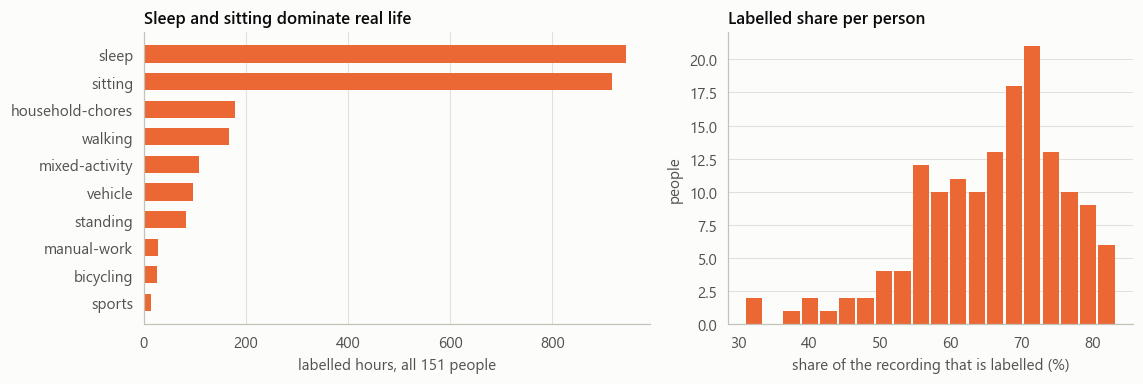

In [26]:
annotation_seconds = pd.DataFrame([s['annotation_seconds'] for s in c24_summaries]).fillna(0).sum()
annotation_hours = annotation_seconds.rename_axis('annotation').reset_index(name='seconds').merge(dictionary, on='annotation')
annotation_hours['hours'] = seconds_to_hours(annotation_hours['seconds'])

by_specific = annotation_hours.groupby('label:WillettsSpecific2018')['hours'].sum()
by_walmsley = annotation_hours.groupby('label:Walmsley2020')['hours'].sum()
people_with_label = c24.groupby('label_specific', observed=True)['participant_id'].nunique()
display(pd.DataFrame({'hours': by_specific, 'percent': 100 * by_specific / by_specific.sum(), 'people with any': people_with_label}).sort_values('hours', ascending=False))

crosstab = annotation_hours.pivot_table(index='label:WillettsSpecific2018', columns='label:Walmsley2020', values='hours', aggfunc='sum', fill_value=0)
print('labelled hours: specific activity (rows) inside each Walmsley class (columns)')
display(crosstab[['sleep', 'sedentary', 'light', 'moderate-vigorous']].round(0).astype(int))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), gridspec_kw={'width_ratios': [1.25, 1]})
hbar(axes[0], by_specific, DATASET_COLOURS['Capture-24'], 'labelled hours, all 151 people')
axes[0].set_title('Sleep and sitting dominate real life')
axes[1].hist(c24_summary['labelled_pct'], bins=20, color=DATASET_COLOURS['Capture-24'], rwidth=0.88)
axes[1].set(xlabel='share of the recording that is labelled (%)', ylabel='people')
axes[1].set_title('Labelled share per person')
axes[1].grid(axis='x', visible=False)
fig.tight_layout()
plt.show()

## 2.5 Time of day

`context.md` expects time of day to matter for telling sleep from inactivity. Capture-24 is the only one of the three datasets with whole days of recording, so it's the only one that can test this.

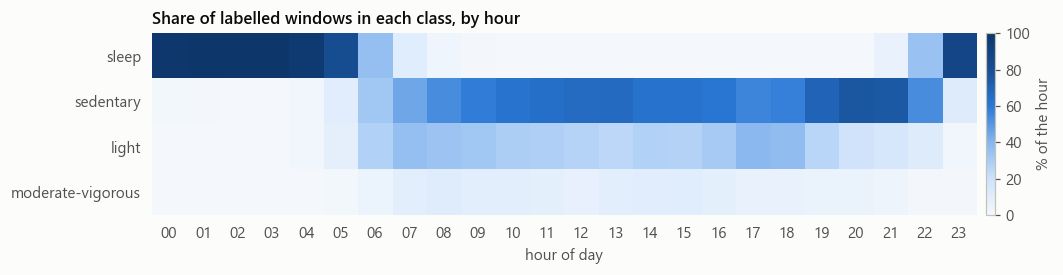

window_start,0,3,6,9,12,15,18,21
label_walmsley,,,,,,,,
sleep,98.700,100.000,35.800,0.800,0.000,0.000,0.000,6.000
sedentary,1.100,0.000,32.300,58.400,66.400,62.900,57.400,74.800
light,0.200,0.000,27.500,32.100,26.800,27.100,36.800,15.500
moderate-vigorous,0.000,0.000,4.400,8.800,6.800,10.000,5.800,3.600


In [27]:
hours = c24['window_start'].dt.hour
by_hour = pd.crosstab(c24['label_walmsley'].astype(str), hours, normalize='columns').reindex(['sleep', 'sedentary', 'light', 'moderate-vigorous']) * 100

fig, ax = plt.subplots(figsize=(10.5, 2.6))
image = ax.imshow(by_hour.to_numpy(), aspect='auto', cmap=BLUES, vmin=0, vmax=100)
ax.set_xticks(range(24), [f'{h:02d}' for h in by_hour.columns])
ax.set_yticks(range(4), by_hour.index)
ax.grid(False)
ax.spines[['left', 'bottom']].set_visible(False)
ax.set_xlabel('hour of day')
ax.set_title('Share of labelled windows in each class, by hour')
fig.colorbar(image, ax=ax, label='% of the hour', pad=0.01)
fig.tight_layout()
plt.show()
display(by_hour.iloc[:, ::3].round(1))

## 2.6 Feature values per activity

Medians across all windows. `mag_mean` barely moves between classes, while the spread features change a lot. Compare `standing` with `sitting`, because this is the case the current models find hardest.

In [28]:
order_specific = ['walking', 'bicycling', 'sports', 'manual-work', 'household-chores', 'mixed-activity', 'standing', 'vehicle', 'sitting', 'sleep']
display(c24.groupby('label_specific', observed=True)[SHOW].median().reindex(order_specific))
print('same features for the 4 Walmsley classes:')
display(c24.groupby('label_walmsley', observed=True)[SHOW].median().reindex(['moderate-vigorous', 'light', 'sedentary', 'sleep']))

age_mix = pd.crosstab(c24['age_bin'], c24['label_walmsley'], normalize='index').reindex(columns=['sleep', 'sedentary', 'light', 'moderate-vigorous']) * 100
print('share of windows per class, by age bin (%):')
display(age_mix.reindex(c24_ages).round(1))

,mag_mean,mag_std,mag_range,axes_std,jerk_std,dom_freq,band_0p5_3hz
label_specific,,,,,,,
walking,1.024,0.174,0.922,0.363,4.441,1.953,0.537
bicycling,1.050,0.230,1.374,0.419,14.432,10.938,0.087
sports,1.040,0.212,1.235,0.486,6.172,1.953,0.492
manual-work,1.027,0.177,1.033,0.422,5.500,1.953,0.406
household-chores,1.020,0.143,0.834,0.397,4.568,1.953,0.394
mixed-activity,1.022,0.174,0.898,0.330,4.427,1.953,0.510
standing,1.005,0.041,0.259,0.113,1.371,2.734,0.292
vehicle,1.005,0.066,0.376,0.111,2.793,2.734,0.285
sitting,1.001,0.011,0.075,0.034,0.526,4.688,0.142


same features for the 4 Walmsley classes:


,mag_mean,mag_std,mag_range,axes_std,jerk_std,dom_freq,band_0p5_3hz
label_walmsley,,,,,,,
moderate-vigorous,1.038,0.249,1.205,0.406,6.534,1.953,0.513
light,1.017,0.128,0.733,0.327,3.726,1.953,0.414
sedentary,1.001,0.014,0.096,0.043,0.641,4.297,0.151
sleep,1.000,0.003,0.018,0.006,0.189,5.859,0.120


share of windows per class, by age bin (%):


label_walmsley,sleep,sedentary,light,moderate-vigorous
age_bin,,,,
18-29,38.900,41.500,15.200,4.400
30-37,38.900,36.400,20.000,4.700
38-52,36.400,39.000,20.100,4.600
53+,32.900,41.800,19.600,5.700


---
# Part 3: GOTOV

35 older adults following a scripted protocol, wearing several devices at once ([Paraschiakos et al.](https://doi.org/10.1007/s11257-020-09268-2)). This is the only one of the three datasets aimed at older people, and it has actual ages rather than bins.

## 3.1 What is in the archive

In [29]:
activity_zip = zipfile.ZipFile(E.GOTOV_DIR / 'Activity_Measurements.zip')
energy_zip = zipfile.ZipFile(E.GOTOV_DIR / 'Energy_Expenditure_Measurements.zip')
members = [i for i in activity_zip.infolist() if i.filename.endswith('.csv') and not i.filename.startswith('__MACOSX')]


def header(archive, name):
    with archive.open(name) as f:
        return [c.strip().strip('"') for c in f.readline().decode().split(',')]


# .lower() because one ankle file is spelled 'GENEACtiv' in the archive
inventory = pd.DataFrame([{'file type': m.filename.split('-', 1)[1].replace('.csv', '').lower(), 'MB': m.file_size / 1e6} for m in members])
display(inventory.groupby('file type')['MB'].agg(participants='count', total_MB='sum').round(0))

wrist_columns = header(activity_zip, E.gotov_wrist_members(activity_zip)[0])
print('GENEActiv wrist/ankle/chest columns:', wrist_columns)

equivital_names = sorted(m.filename for m in members if m.filename.endswith('equivital.csv'))
equivital_headers = {n: header(activity_zip, n) for n in equivital_names}
always = set.intersection(*map(set, equivital_headers.values()))
sometimes = sorted(set.union(*map(set, equivital_headers.values())) - always)
print(f'\nEquivital (chest): {len(always)} columns in every file. Only in some files: {sometimes}')

example_equivital = pd.read_csv(activity_zip.open(equivital_names[-1]), nrows=400_000, low_memory=False)
filled = 100 * example_equivital.notna().mean()
print(f'\nshare of Equivital rows with a value, first 400,000 rows of {equivital_names[-1].split("/")[1]} (each channel has its own rate, so the rest are blank):')
print(filled.drop(['Unnamed: 0', 'time']).round(2).to_string())

energy_names = [n for n in energy_zip.namelist() if n.endswith('.csv') and not n.startswith('__MACOSX')]
print(f'\nCOSMED energy files: {len(energy_names)} participants, columns:')
print(header(energy_zip, energy_names[0]))

,participants,total_MB
file type,,
equivital,34,"5,622.000"
geneactiv-ankle,34,793.000
geneactiv-chest,29,595.000
geneactiv-wrist,35,833.000


GENEActiv wrist/ankle/chest columns: ['', 'time', 'x', 'y', 'z', 'labels']

Equivital (chest): 29 columns in every file. Only in some files: ['Apnea', 'Breathing.rate.high.low', 'Button.Press.Event', 'Fall.Alarm', 'Irregular.rhythm.HR', 'Low.Battery.Internal']

share of Equivital rows with a value, first 400,000 rows of GOTOV36 (each channel has its own rate, so the rest are blank):
HR..bpm.                                   0.080
BR..rpm.                                   0.080
Skin.Temperature...IR.Thermometer...C.     0.080
Body.Position                              0.080
Ambulation.Status                          0.080
Alert                                      0.080
PWI                                        0.080
Device.Indications                         0.080
Subject.Indications                        0.050
Belt.Off.alert                             0.080
Low.HR.Confidence                          0.080
HR.Confidence                              0.080
Low.BR.Confidence         

**SilverGuard can only use the wrist file.** It's the same kind of device and placement as our watch. The ankle, chest, Equivital and COSMED data can't come from a single wrist sensor. They aren't useless, though: the COSMED `METS` column measures how hard someone is really working, which could help check "active" labels later.

## 3.2 Who took part, and does it match the documentation?

age        height       weight           bmi         n
      mean   std    mean   std   mean    std   mean   std    
sex                                                          
F   66.700 5.800 166.900 5.600 73.700  6.100 26.500 2.300  14
M   64.900 3.900 178.600 5.100 88.000 10.000 27.600 2.900  21

age range 59.5 to 81.3, median 64.6
age 70 or over: 5 of 35.  Age 75 or over: 1
younger than the stated minimum of 60: [{'ID': 'GOTOV06', 'age': 59.7}, {'ID': 'GOTOV18', 'age': 59.5}]
recorded between 2015-12-02 and 2016-05-30 (the protocol PDF says February to May 2015)
devices present: {'gaWrist': 35, 'gaAnkle': 34, 'gaChest': 29, 'equivital': 34, 'cosmed': 31}


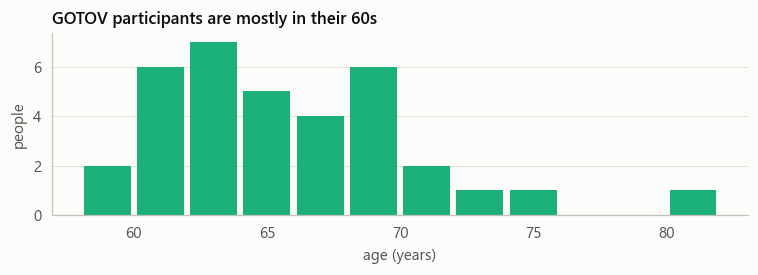

In [30]:
gotov_people = pd.read_csv(E.GOTOV_DIR / 'GOTOV_DataSummary.csv', parse_dates=['trial_date'], dayfirst=True)
gotov_people['sex'] = gotov_people['gender'].map({'vrouw': 'F', 'man': 'M'})   # the file uses Dutch: vrouw = woman
display(gotov_people.groupby('sex')[['age', 'height', 'weight', 'bmi']].agg(['mean', 'std']).round(1).assign(n=gotov_people.groupby('sex').size()))
print(f"age range {gotov_people['age'].min()} to {gotov_people['age'].max()}, median {gotov_people['age'].median():.1f}")
print(f"age 70 or over: {(gotov_people['age'] >= 70).sum()} of {len(gotov_people)}.  Age 75 or over: {(gotov_people['age'] >= 75).sum()}")
print('younger than the stated minimum of 60:', gotov_people.loc[gotov_people['age'] < 60, ['ID', 'age']].to_dict('records'))
print('recorded between', gotov_people['trial_date'].min().date(), 'and', gotov_people['trial_date'].max().date(), '(the protocol PDF says February to May 2015)')
print('devices present:', gotov_people[['gaWrist', 'gaAnkle', 'gaChest', 'equivital', 'cosmed']].sum().to_dict())

fig, ax = plt.subplots(figsize=(7, 2.6))
ax.hist(gotov_people['age'], bins=np.arange(58, 84, 2), color=DATASET_COLOURS['GOTOV'], rwidth=0.88)
ax.set(xlabel='age (years)', ylabel='people')
ax.set_title('GOTOV participants are mostly in their 60s')
ax.grid(axis='x', visible=False)
fig.tight_layout()
plt.show()

## 3.3 Sampling rate and data quality

The documentation gives the rate as both 83 Hz and 88 Hz, so this measures it from the timestamps. It also checks for repeated recordings, because some files have exactly the same number of rows.

In [32]:
gotov = E.build_gotov()
gotov_summary = pd.read_parquet(E.CACHE / 'gotov_summary.parquet').set_index('participant_id')
gotov_bouts = pd.read_parquet(E.CACHE / 'gotov_bouts.parquet')

print(f"{len(gotov_summary)} wrist files, {gotov_summary['hours'].sum():.1f} hours recorded, {(gotov_summary['hours'] * gotov_summary['labelled_pct'] / 100).sum():.1f} hours labelled")
print(f"{len(gotov):,} windows of {WINDOW_S} s ({len(gotov) * WINDOW_S / 3600:.1f} hours)\n")
display(gotov_summary[['rows', 'hours', 'labelled_pct', 'median_dt_ms', 'mean_dt_ms', 'fs_from_mean_dt', 'min_dt_ms', 'max_dt_ms', 'max_abs_g', 'clipped_pct']].describe().loc[['min', '50%', 'max']])
print(f"missing x/y/z values: {gotov_summary['nan_values'].sum()}.  Time gaps over 100 ms: {gotov_summary['time_gaps'].sum()}")
print(f"median step would suggest {1000 / gotov_summary['median_dt_ms'].median():.1f} Hz, but the mean step gives {gotov_summary['fs_from_mean_dt'].median():.1f} Hz")

same_rows = gotov_summary.groupby('rows').filter(lambda g: len(g) > 1)
print('\nfiles with the same row count:',
      {k: list(v) for k, v in same_rows.groupby('rows').groups.items()})
print('files with identical x/y/z data:', int(gotov_summary['xyz_md5'].duplicated().sum()))

35 wrist files, 50.2 hours recorded, 24.2 hours labelled
33,809 windows of 2.56 s (24.0 hours)



,rows,hours,labelled_pct,median_dt_ms,mean_dt_ms,fs_from_mean_dt,min_dt_ms,max_dt_ms,max_abs_g,clipped_pct
min,"181,972.000",0.590,17.476,12.000,11.667,85.714,4.000,12.000,3.704,0.000
50%,"433,116.000",1.404,55.123,12.000,11.667,85.714,4.000,15.000,7.965,0.000
max,"1,615,661.000",5.236,62.600,12.000,11.667,85.715,8.000,15.000,8.171,0.003


missing x/y/z values: 0.  Time gaps over 100 ms: 0
median step would suggest 83.3 Hz, but the mean step gives 85.7 Hz

files with the same row count: {403716: ['GOTOV05', 'GOTOV09'], 567430: ['GOTOV07', 'GOTOV17']}
files with identical x/y/z data: 0


## 3.4 The activities, and how much each person really has

`GOTOV_DataSummary.csv` says how long each person did each activity. This compares that claim with the labels actually present in the wrist files, because a test set is only as good as what's really in it.

total: 1,579 min claimed, 1,451 min in the wrist files
people missing more than 5 minutes:


,claimed_min,in_wrist_file_min,missing_min
GOTOV27,53.600,21.200,32.300
GOTOV30,53.200,21.700,31.400
GOTOV18,53.900,25.400,28.600
GOTOV15,42.800,21.300,21.500
GOTOV09,55.500,42.500,13.000


,minutes,people,windows,people per doc
walkingSlow,104.300,21,2441,25
walkingNormal,104.600,21,2446,25
walkingFast,99.300,21,2322,25
walkingStairsUp,10.100,35,209,35
step,23.200,32,525,32
cycling,217.800,18,5096,22
vacuumCleaning,95.200,32,2222,35
stakingShelves,96.700,33,2257,35
dishwashing,105.000,35,2450,35
standing,66.300,35,1525,35


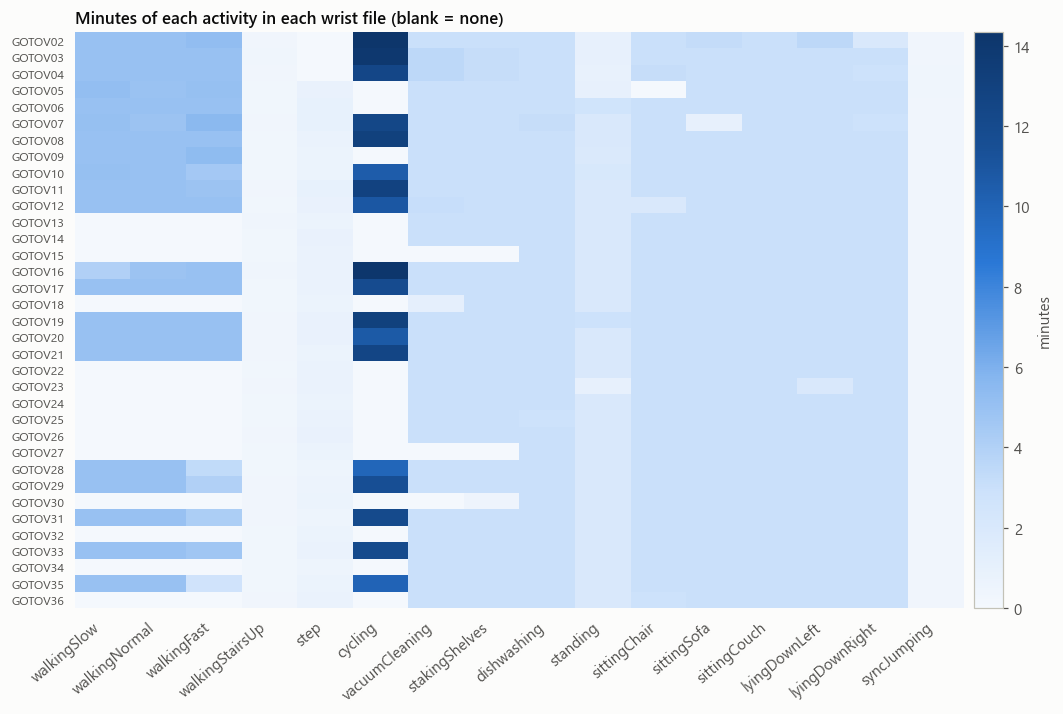

In [33]:
GOTOV_ORDER = ['walkingSlow', 'walkingNormal', 'walkingFast', 'walkingStairsUp', 'step', 'cycling', 'vacuumCleaning', 'stakingShelves',
               'dishwashing', 'standing', 'sittingChair', 'sittingSofa', 'sittingCouch', 'lyingDownLeft', 'lyingDownRight', 'syncJumping']

actual = gotov_bouts.pivot_table(index='participant_id', columns='label', values='seconds', aggfunc='sum', fill_value=0).reindex(columns=GOTOV_ORDER, fill_value=0)
claimed = gotov_people.set_index('ID')
claimed = claimed.assign(standing=claimed['standing'] + claimed['standing.1'])[GOTOV_ORDER]

totals = pd.DataFrame({'claimed_min': claimed.sum(axis=1) / 60, 'in_wrist_file_min': actual.sum(axis=1) / 60})
totals['missing_min'] = totals['claimed_min'] - totals['in_wrist_file_min']
print(f"total: {totals['claimed_min'].sum():,.0f} min claimed, {totals['in_wrist_file_min'].sum():,.0f} min in the wrist files")
print('people missing more than 5 minutes:')
display(totals[totals['missing_min'] > 5].sort_values('missing_min', ascending=False).round(1))

activity_stats = pd.DataFrame({'minutes': actual.sum() / 60, 'people': (actual > 0).sum(), 'windows': gotov['label'].value_counts().reindex(GOTOV_ORDER),
                               'people per doc': (claimed > 0).sum()})
display(activity_stats.round(1))

fig, ax = plt.subplots(figsize=(10.5, 6.6))
image = ax.imshow(actual.to_numpy() / 60, aspect='auto', cmap=BLUES, vmin=0)
ax.set_xticks(range(len(GOTOV_ORDER)), GOTOV_ORDER, rotation=40, ha='right')
ax.set_yticks(range(len(actual)), actual.index, fontsize=8)
ax.grid(False)
ax.spines[['left', 'bottom']].set_visible(False)
ax.set_title('Minutes of each activity in each wrist file (blank = none)')
fig.colorbar(image, ax=ax, label='minutes', pad=0.01)
fig.tight_layout()
plt.show()

## 3.5 One whole session

One participant from start to end, reduced to the spread of the magnitude every 5 seconds, with the labelled activities marked. The unlabelled stretches are also useful to see: that's the time between activities, when people were moving or waiting.

,Unnamed: 0,time,x,y,z,labels
0,62572,"1,455,183,182,000.000",-0.340,0.941,0.116,NaN
1,62573,"1,455,183,182,008.000",-0.332,0.921,0.143,NaN
2,62574,"1,455,183,182,020.000",-0.336,0.929,0.147,NaN


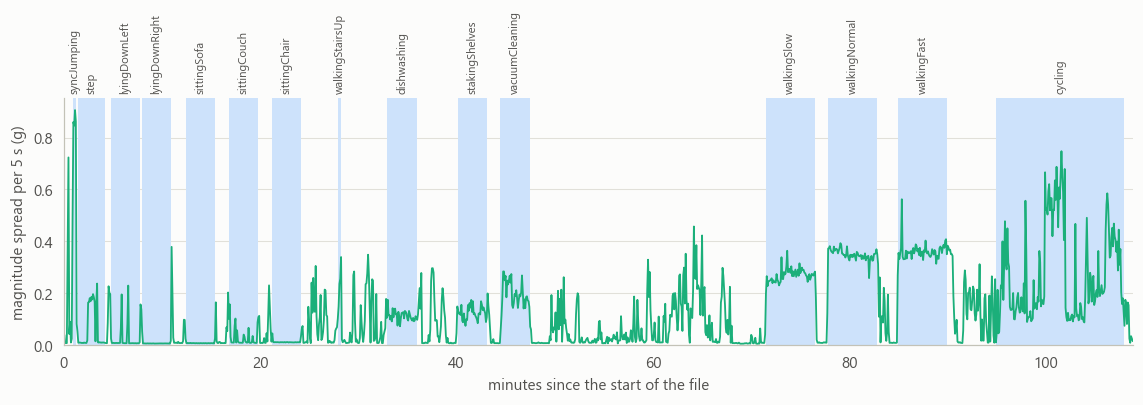

In [34]:
gotov_example = 'GOTOV08'
raw = pd.read_csv(activity_zip.open(f'Activity_Measurements/{gotov_example}/{gotov_example}-GENEActiv-wrist.csv'), low_memory=False)
display(raw.head(3))
minutes = (raw['time'] - raw['time'].iloc[0]) / 60000
magnitude_raw = np.sqrt(raw['x'] ** 2 + raw['y'] ** 2 + raw['z'] ** 2)
spread = magnitude_raw.groupby((minutes * 12).astype(int)).std()
labels_raw = raw['labels'].fillna('')
edges = np.flatnonzero(labels_raw.to_numpy()[1:] != labels_raw.to_numpy()[:-1]) + 1

fig, ax = plt.subplots(figsize=(10.5, 3.8))
last_label_at = -10
for start, end in zip(np.r_[0, edges], np.r_[edges, len(raw)]):
    if labels_raw.iloc[start]:
        ax.axvspan(minutes.iloc[start], minutes.iloc[end - 1], color='#cde2fb', lw=0)
        middle = (minutes.iloc[start] + minutes.iloc[end - 1]) / 2
        if middle - last_label_at > 1.5:     # the first few bouts are too close together to name them all
            ax.text(middle, 1.02, labels_raw.iloc[start], rotation=90, fontsize=7.5, ha='center', va='bottom', color=INK_2, transform=ax.get_xaxis_transform())
            last_label_at = middle
ax.plot(spread.index / 12, spread.to_numpy(), color=DATASET_COLOURS['GOTOV'], lw=1.2)
ax.set(xlabel='minutes since the start of the file', ylabel='magnitude spread per 5 s (g)', xlim=(0, minutes.iloc[-1]), ylim=(0, None))
ax.grid(axis='x', visible=False)
fig.tight_layout()
plt.show()

## 3.6 Feature values per activity

In [35]:
display(gotov.groupby('label')[SHOW].median().reindex(GOTOV_ORDER))

,mag_mean,mag_std,mag_range,axes_std,jerk_std,dom_freq,band_0p5_3hz
label,,,,,,,
walkingSlow,1.044,0.251,1.027,0.303,4.676,1.562,0.763
walkingNormal,1.081,0.310,1.226,0.377,5.526,1.953,0.796
walkingFast,1.148,0.325,1.357,0.417,6.346,1.953,0.749
walkingStairsUp,1.071,0.215,1.083,0.450,5.226,1.562,0.601
step,1.022,0.182,0.890,0.239,3.998,1.953,0.580
cycling,1.048,0.150,0.918,0.297,9.107,11.719,0.103
vacuumCleaning,1.116,0.226,1.221,0.489,6.625,1.172,0.545
stakingShelves,1.039,0.204,1.149,0.651,5.806,1.172,0.521
dishwashing,1.064,0.187,1.082,0.515,5.547,1.953,0.356


---
# Part 4: The comparison

## 4.1 At a glance

The measured rows are computed from the data above. The study details come from each dataset's documentation.

In [36]:
at_a_glance = pd.DataFrame({
    'UCI-HAR': {
        'Where it was worn': 'Waist',
        'Device': 'Samsung Galaxy S II (phone)',
        'Setting': 'Scripted, lab',
        'People': uci['participant_id'].nunique(),
        'Ages': '19 to 48',
        'Older adults': 'None',
        'Rate from documentation': '50 Hz',
        'Rate measured': 'Not checkable (no timestamps)',
        'Largest reading': f"{uci['acc_max_abs'].max():.2f} g",
        'Gyroscope': 'Yes',
        'Other channels': 'None',
        'Timestamps': 'No, windows only',
        'Activity labels': uci['label'].nunique(),
        'Label source': 'Video',
        'Signal time': f"{uci['hours_new'].sum():.1f} h",
        'Per person': f"about {windows_per_person.median() * UCI_OVERLAP_S / 60:.0f} min",
        'Contains sleep': 'No',
    },
    'Capture-24': {
        'Where it was worn': 'Wrist (dominant)',
        'Device': 'Axivity AX3',
        'Setting': 'Free-living, about 24 h',
        'People': len(c24_summary),
        'Ages': 'Bins: 18-29 to 53+',
        'Older adults': f"{(c24_meta['age'] == '53+').sum()} people aged 53+ (not split further)",
        'Rate from documentation': '100 Hz',
        'Rate measured': f"{1000 / c24_summary['median_dt_ms'].median():.1f} Hz",
        'Largest reading': f"{c24_summary['max_abs_g'].max():.2f} g",
        'Gyroscope': 'No',
        'Other channels': 'None',
        'Timestamps': 'Yes',
        'Activity labels': f"{len(dictionary)} free-text, grouped to 4 to 11",
        'Label source': 'Wearable camera + sleep diary',
        'Signal time': f"{len(c24) * WINDOW_S / 3600:,.0f} h in windows",
        'Per person': f"about {c24_summary['hours'].median():.0f} h",
        'Contains sleep': 'Yes',
    },
    'GOTOV': {
        'Where it was worn': 'Right wrist (also ankle, chest)',
        'Device': 'GENEActiv',
        'Setting': 'Scripted, indoor and outdoor',
        'People': len(gotov_summary),
        'Ages': f"{gotov_people['age'].min()} to {gotov_people['age'].max()}",
        'Older adults': f"All; {(gotov_people['age'] >= 70).sum()} aged 70+",
        'Rate from documentation': '83 Hz and 88 Hz (conflicting)',
        'Rate measured': f"{gotov_summary['fs_from_mean_dt'].median():.1f} Hz",
        'Largest reading': f"{gotov_summary['max_abs_g'].max():.2f} g",
        'Gyroscope': 'No',
        'Other channels': 'ECG, HR, breathing, skin temp, energy use',
        'Timestamps': 'Yes',
        'Activity labels': gotov['label'].nunique(),
        'Label source': 'Protocol start and end times',
        'Signal time': f"{len(gotov) * WINDOW_S / 3600:.1f} h in windows",
        'Per person': f"about {actual.sum(axis=1).median() / 60:.0f} min labelled",
        'Contains sleep': 'No',
    },
})
display(at_a_glance.style.set_properties(**{'text-align': 'left'}))

,UCI-HAR,Capture-24,GOTOV
Where it was worn,Waist,Wrist (dominant),"Right wrist (also ankle, chest)"
Device,Samsung Galaxy S II (phone),Axivity AX3,GENEActiv
Setting,"Scripted, lab","Free-living, about 24 h","Scripted, indoor and outdoor"
People,30,151,35
Ages,19 to 48,Bins: 18-29 to 53+,59.5 to 81.3
Older adults,None,34 people aged 53+ (not split further),All; 5 aged 70+
Rate from documentation,50 Hz,100 Hz,83 Hz and 88 Hz (conflicting)
Rate measured,Not checkable (no timestamps),100.0 Hz,85.7 Hz
Largest reading,2.20 g,8.67 g,8.17 g
Gyroscope,Yes,No,No


## 4.2 Which features can each dataset support?

This is the direct answer to "what features are there". ✓ means it can be computed from that dataset's raw data, and ✗ means it can't. SilverGuard's own sensor has an accelerometer and a gyroscope, so its column shows which features the device could use.

In [37]:
accel_only_561 = (~uci_561['needs_gyro']).sum()
gyro_561 = uci_561['needs_gyro'].sum()

availability = pd.DataFrame([
    # name, UCI, Capture-24, GOTOV, SilverGuard, used for
    ['Accel x, y, z',                                 '✓', '✓', '✓', '✓', 'Everything below'],
    ['Magnitude features (the 5 in features.py)',     '✓', '✓', '✓', '✓', 'Current models'],
    ['ENMO',                                          '✓', '✓', '✓', '✓', 'Baseline in context.md'],
    ['Axis spread, jerk',                             '✓', '✓', '✓', '✓', 'Slow arm turning, sharpness'],
    ['Frequency content',                             '✓', '✓', '✓', '✓', 'Steps vs other movement'],
    ['Wrist tilt (gravity direction)',                '✓ (waist)', '✓', '✓', '✓', 'Posture; sleep vs sitting'],
    ['Gyro x, y, z and any feature built on them',    '✓', '✗', '✗', '✓', 'Falls (sudden rotation)'],
    ['Time of day',                                   '✗', '✓', '✗ (scripted session)', '✓', 'Sleep vs inactivity'],
    ['Continuous hours and days',                     '✗', '✓', '✗', '✓', 'Inactivity alert testing'],
    ['Actual age',                                    '✗', '✗ (bins)', '✓', '—', 'Reporting by age'],
    ['Sex',                                           '✗', '✓', '✓', '—', 'Reporting by sex'],
    ['Heart rate, breathing, ECG',                    '✗', '✗', '✓ (chest)', '✗', 'Not available on our watch'],
    ['Measured energy use (METS)',                    '✗', '✗', '✓ (31 people)', '✗', 'Could check "active" labels'],
    [f'UCI ready-made features: accelerometer ({accel_only_561})', '✓', 'recompute', 'recompute', 'recompute', 'Same formulas, new values'],
    [f'UCI ready-made features: gyroscope ({gyro_561})', '✓', '✗', '✗', 'recompute', 'Only testable on UCI'],
], columns=['Feature', 'UCI-HAR', 'Capture-24', 'GOTOV', 'SilverGuard', 'Used for']).set_index('Feature')
display(availability.style.set_properties(**{'text-align': 'left'}))
print(f'the two new datasets can support {accel_only_561} of the 561 UCI features ({100 * accel_only_561 / 561:.0f}%), once recomputed from raw signals')

,UCI-HAR,Capture-24,GOTOV,SilverGuard,Used for
Feature,,,,,
"Accel x, y, z",✓,✓,✓,✓,Everything below
Magnitude features (the 5 in features.py),✓,✓,✓,✓,Current models
ENMO,✓,✓,✓,✓,Baseline in context.md
"Axis spread, jerk",✓,✓,✓,✓,"Slow arm turning, sharpness"
Frequency content,✓,✓,✓,✓,Steps vs other movement
Wrist tilt (gravity direction),✓ (waist),✓,✓,✓,Posture; sleep vs sitting
"Gyro x, y, z and any feature built on them",✓,✗,✗,✓,Falls (sudden rotation)
Time of day,✗,✓,✗ (scripted session),✓,Sleep vs inactivity
Continuous hours and days,✗,✓,✗,✓,Inactivity alert testing


the two new datasets can support 348 of the 561 UCI features (62%), once recomputed from raw signals


## 4.3 Lining the labels up

The three label sets don't match, so this maps them onto shared classes. Some of the matches aren't exact, and they're listed under the table because they affect how far the comparison can be trusted.

,UCI-HAR,Capture-24,GOTOV
common,,,
walking,16.700,6.500,21.300
stairs,28.600,0.000,2.200
cycling,0.000,1.000,15.100
household,0.000,7.000,20.500
standing,18.500,3.200,4.500
sitting,17.300,35.800,21.300
lying/sleep,18.900,37.000,14.400
vehicle,0.000,3.800,0.000
other,0.000,5.800,0.700


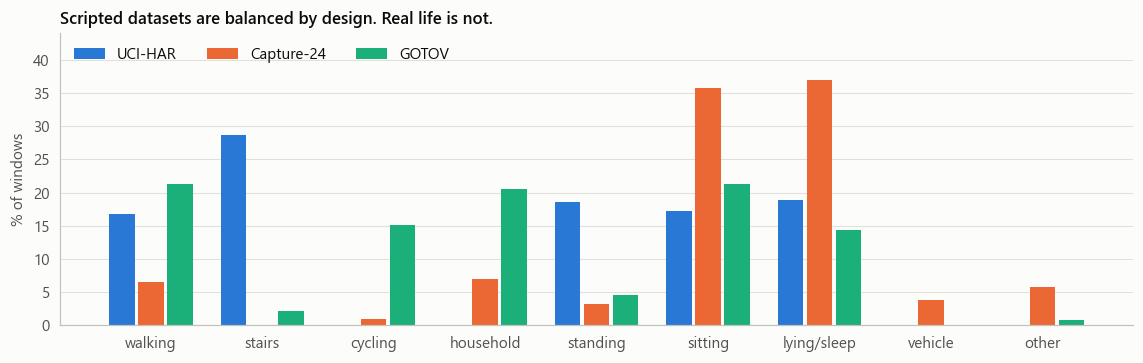

In [38]:
UCI_TO_COMMON = {'WALKING': 'walking', 'WALKING_UPSTAIRS': 'stairs', 'WALKING_DOWNSTAIRS': 'stairs', 'STANDING': 'standing', 'SITTING': 'sitting', 'LAYING': 'lying/sleep'}
C24_TO_COMMON = {'walking': 'walking', 'bicycling': 'cycling', 'household-chores': 'household', 'standing': 'standing', 'sitting': 'sitting', 'sleep': 'lying/sleep',
                 'vehicle': 'vehicle', 'sports': 'other', 'manual-work': 'other', 'mixed-activity': 'other'}
GOTOV_TO_COMMON = {'walkingSlow': 'walking', 'walkingNormal': 'walking', 'walkingFast': 'walking', 'walkingStairsUp': 'stairs', 'step': 'stairs', 'cycling': 'cycling',
                   'vacuumCleaning': 'household', 'stakingShelves': 'household', 'dishwashing': 'household', 'standing': 'standing',
                   'sittingChair': 'sitting', 'sittingSofa': 'sitting', 'sittingCouch': 'sitting', 'lyingDownLeft': 'lying/sleep', 'lyingDownRight': 'lying/sleep', 'syncJumping': 'other'}
COMMON = ['walking', 'stairs', 'cycling', 'household', 'standing', 'sitting', 'lying/sleep', 'vehicle', 'other']

uci['common'] = uci['label'].map(UCI_TO_COMMON)
c24['common'] = c24['label_specific'].astype(str).map(C24_TO_COMMON)
gotov['common'] = gotov['label'].map(GOTOV_TO_COMMON)
c24_dev = c24[~c24['participant_id'].isin(TEST_PEOPLE)]
assert uci['common'].notna().all() and c24['common'].notna().all() and gotov['common'].notna().all()
DATASETS = {'UCI-HAR': uci, 'Capture-24': c24, 'GOTOV': gotov}

shares = pd.DataFrame({name: 100 * d['common'].value_counts(normalize=True) for name, d in DATASETS.items()}).reindex(COMMON).fillna(0)
display(shares.round(1))

fig, ax = plt.subplots(figsize=(10.5, 3.4))
bar_w = 0.26
for i, name in enumerate(DATASETS):
    ax.bar(np.arange(len(COMMON)) + (i - 1) * bar_w, shares[name], bar_w * 0.88, color=DATASET_COLOURS[name], label=name)
ax.set_xticks(range(len(COMMON)), COMMON)
ax.set_ylabel('% of windows')
ax.grid(axis='x', visible=False)
ax.set_ylim(0, 44)
ax.legend(ncols=3, loc='upper left')
ax.set_title('Scripted datasets are balanced by design. Real life is not.')
fig.tight_layout()
plt.show()

**Where the mapping isn't a perfect match:**

- **Capture-24 `sleep` vs lying awake:** UCI and GOTOV participants lay down awake for a few minutes, while Capture-24 people were actually asleep. The two are shown as one class, but expect sleep to be stiller. Capture-24's lying-awake annotations are counted as `sitting` (see 2.3).
- **`stairs`:** Capture-24 has no separate class. The dictionary puts stairs annotations into `walking` or `mixed-activity` (see 2.3).
- **`walking`:** in UCI and GOTOV, it's walking on request. In Capture-24, it's whatever the camera showed, including walking while carrying things.
- **`household`:** GOTOV is three specific chores, while Capture-24 is a broad group.

## 4.4 Does each sensor read 1 g when still?

A still sensor should read exactly 1 g. Any error goes straight into ENMO, whose first cut-point is only 45 mg, so this checks each person's still windows (where `mag_std` is under 13 mg).

In [39]:
rows = []
for name, d in DATASETS.items():
    still = d[d['mag_std'] < 0.013]
    per_person = (still.groupby('participant_id', observed=True)['mag_mean'].median() - 1) * 1000
    rows.append({'dataset': name, 'people': per_person.size, 'median error (mg)': per_person.median(), '5th percentile': per_person.quantile(0.05),
                 '95th percentile': per_person.quantile(0.95), 'worst person': per_person.abs().max(), 'people off by over 45 mg': int((per_person.abs() > 45).sum())})
display(pd.DataFrame(rows).set_index('dataset').round(1))

print('median mag_mean of still windows per posture (mg away from 1 g). A device with a good calibration should not change with posture:')
posture = pd.DataFrame({name: (d[(d['mag_std'] < 0.013) & d['common'].isin(['standing', 'sitting', 'lying/sleep'])].groupby('common')['mag_mean'].median() - 1) * 1000
                        for name, d in DATASETS.items()})
display(posture.round(1))

,people,median error (mg),5th percentile,95th percentile,worst person,people off by over 45 mg
dataset,,,,,,
UCI-HAR,30,23.700,12.400,29.600,33.700,0
Capture-24,151,-0.100,-18.300,5.100,57.700,2
GOTOV,35,13.600,-4.900,25.100,26.900,0


median mag_mean of still windows per posture (mg away from 1 g). A device with a good calibration should not change with posture:


,UCI-HAR,Capture-24,GOTOV
common,,,
lying/sleep,9.000,-0.100,12.900
sitting,24.000,-0.300,16.200
standing,32.900,0.100,11.700


**How to read this:** UCI runs about 24 mg high, and its error changes with posture (9 to 33 mg). GOTOV runs about 14 mg high, and its error depends on orientation too: Section 3.6 shows lying on the left at 1.023 g and on the right at 0.992 g, where the main thing that changes is the direction of gravity. Capture-24 sits close to 1 g, so it looks as if it has already been calibrated. These errors are a sizeable fraction of the 45 mg ENMO cut-point, which is why `context.md` says to calibrate the MPU-6050 first.

## 4.5 The same activity on a waist and on a wrist

Ten seconds of raw signal per dataset, on the same scale. This shows the main difference between the datasets better than any summary table.

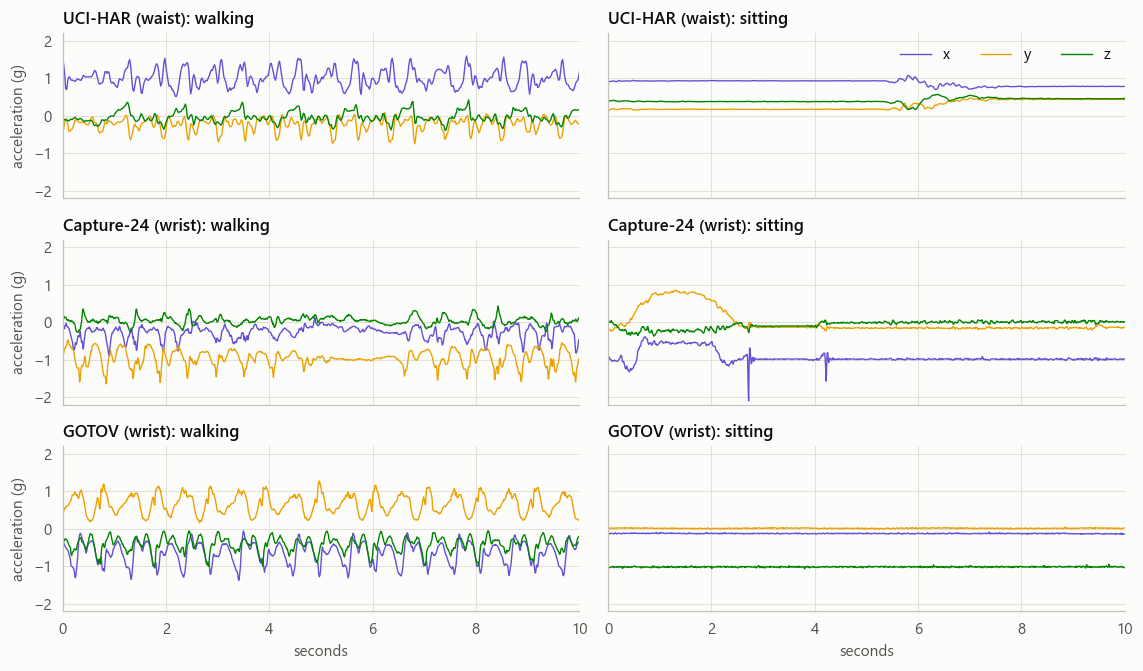

In [40]:
def longest_run(labels, wanted):
    """(start, end) of the longest unbroken stretch of the wanted labels."""
    hits = np.asarray(labels.isin(wanted))
    edges = np.flatnonzero(np.diff(np.r_[0, hits.astype(int), 0]))
    starts, ends = edges[::2], edges[1::2]
    i = (ends - starts).argmax()
    return starts[i], ends[i]


specific = c24_raw['annotation'].astype(object).map(dictionary.set_index('annotation')['label:WillettsSpecific2018'])


def uci_clip(activity, n_windows=8):
    """UCI has no continuous recording. Consecutive windows overlap by half, so stitching the first half of each gives one."""
    subject = pd.read_csv(E.UCI_DIR / 'train' / 'subject_train.txt', header=None)[0]
    y = pd.read_csv(E.UCI_DIR / 'train' / 'y_train.txt', header=None)[0]
    code = {'walking': 1, 'sitting': 4}[activity]
    start = np.flatnonzero((y == code) & (subject == 1))[0]
    axes = {}
    for a in 'xyz':
        windows = pd.read_csv(E.UCI_DIR / 'train' / 'Inertial Signals' / f'total_acc_{a}_train.txt', sep=r'\s+', header=None, skiprows=start, nrows=n_windows).to_numpy()
        axes[a] = windows[:, :64].ravel()
    return axes, 50


def c24_clip(activity):
    start, _ = longest_run(specific, [activity])
    chunk = c24_raw.iloc[start:start + 1000]
    return {a: chunk[a].to_numpy() for a in 'xyz'}, 100


def gotov_clip(activity):
    label = {'walking': 'walkingNormal', 'sitting': 'sittingChair'}[activity]
    start = np.flatnonzero((raw['labels'] == label).to_numpy())[0] + 2000
    chunk = raw.iloc[start:start + 857]
    return {a: chunk[a].to_numpy() for a in 'xyz'}, 1000 / 11.667


clip_makers = {'UCI-HAR (waist)': uci_clip, 'Capture-24 (wrist)': c24_clip, 'GOTOV (wrist)': gotov_clip}
fig, axes = plt.subplots(3, 2, figsize=(10.5, 6.2), sharex=True, sharey=True)
for row, (name, make) in enumerate(clip_makers.items()):
    for col, activity in enumerate(['walking', 'sitting']):
        clip, fs = make(activity)
        ax = axes[row, col]
        for a, values in clip.items():
            ax.plot(np.arange(len(values)) / fs, values, color=AXIS_COLOURS[a], lw=0.9, label=a)
        ax.set_title(f'{name}: {activity}')
        ax.set_xlim(0, 10)
        ax.set_ylim(-2.2, 2.2)
axes[0, 1].legend(ncols=3, loc='upper right')
for ax in axes[:, 0]:
    ax.set_ylabel('acceleration (g)')
for ax in axes[-1, :]:
    ax.set_xlabel('seconds')
fig.tight_layout()
plt.show()

## 4.6 How much movement each class shows

`mag_std` is the feature your device threshold depends on. Each panel below is one class, with one line per dataset, showing the share of windows at or below each `mag_std` value. If datasets looked alike, their lines would sit on top of each other. A line further right means more movement.

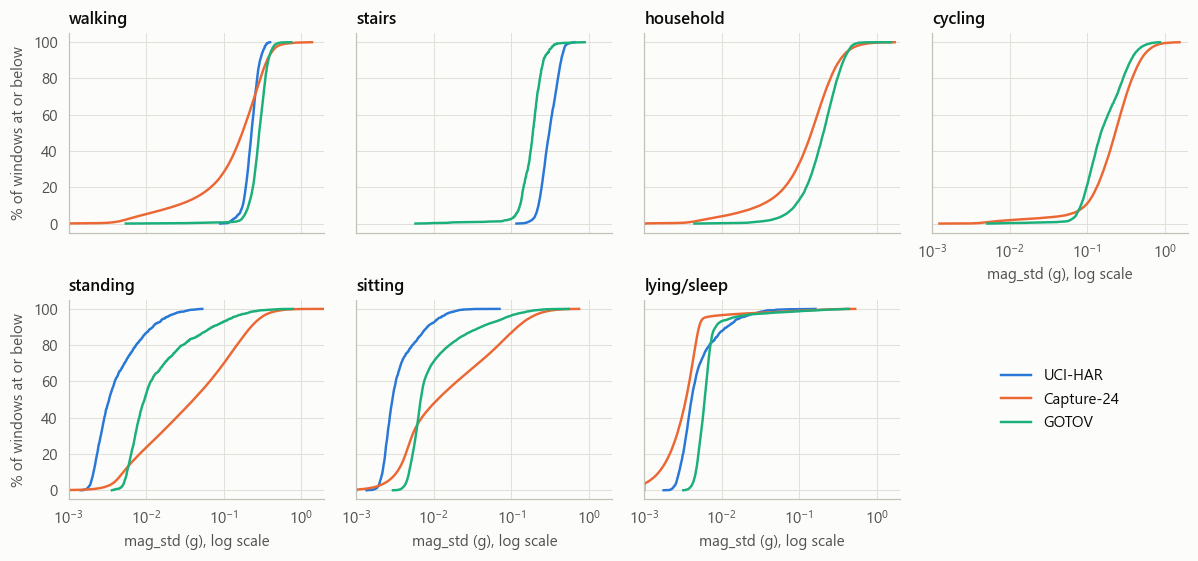

median value per class:


mag_std                  axes_std                 
dataset     UCI-HAR Capture-24 GOTOV  UCI-HAR Capture-24 GOTOV
common                                                        
walking       0.229      0.174 0.288    0.308      0.363 0.367
stairs        0.307        NaN 0.189    0.373        NaN 0.254
cycling         NaN      0.230 0.150      NaN      0.419 0.297
household       NaN      0.143 0.205      NaN      0.397 0.555
standing      0.003      0.041 0.010    0.011      0.113 0.024
sitting       0.003      0.011 0.007    0.009      0.034 0.013
lying/sleep   0.004      0.003 0.006    0.010      0.006 0.011
vehicle         NaN      0.066   NaN      NaN      0.111   NaN
other           NaN      0.177 0.926      NaN      0.352 1.109

In [41]:
panels = ['walking', 'stairs', 'household', 'cycling', 'standing', 'sitting', 'lying/sleep']
fig, axes = plt.subplots(2, 4, figsize=(11, 5.2), sharex=True, sharey=True)
for ax, common in zip(axes.ravel(), panels):
    for name, d in DATASETS.items():
        values = np.sort(d.loc[d['common'] == common, 'mag_std'].to_numpy())
        if len(values) == 0:
            continue
        step = max(1, len(values) // 2000)
        ax.plot(np.maximum(values[::step], 1e-3), np.linspace(0, 100, len(values[::step])), color=DATASET_COLOURS[name], label=name)
    ax.set_title(common)
    ax.set_xscale('log')
    ax.set_xlim(1e-3, 2)
axes[1, 3].axis('off')
handles, legend_labels = axes[0, 0].get_legend_handles_labels()
axes[1, 3].legend(handles, legend_labels, loc='center')
for ax in axes[:, 0]:
    ax.set_ylabel('% of windows at or below')
for ax in axes[1, :3]:
    ax.set_xlabel('mag_std (g), log scale')
axes[0, 3].tick_params(labelbottom=True)
axes[0, 3].set_xlabel('mag_std (g), log scale')
fig.tight_layout()
plt.show()

tidy = pd.concat([d.assign(dataset=name)[['dataset', 'common', 'mag_std', 'axes_std']].astype({'common': str}) for name, d in DATASETS.items()], ignore_index=True)
median_table = tidy.pivot_table(index='common', columns='dataset', values=['mag_std', 'axes_std'], aggfunc='median').reindex(COMMON)[[('mag_std', n) for n in DATASETS] + [('axes_std', n) for n in DATASETS]]
print('median value per class:')
display(median_table.round(3))

**How to read this:** the moving classes have similar shapes, except that about a fifth of real-life Capture-24 walking shows little wrist movement, possibly from carrying things or having hands in pockets. The still classes are where the datasets really differ. For standing, the median `mag_std` is 0.003 g on UCI, 0.010 g on GOTOV and 0.041 g on Capture-24. That's about 14 times more movement than UCI, most likely because people use their hands while standing in daily life. Sitting shows the same pattern to a smaller degree.

## 4.7 Frequency content

Walking repeats, so it shows up as a peak in the frequency spectrum, and that peak is what a frequency feature would detect. Each line is the average spectrum for a class, based on the 2.56 s windows, so the frequency steps are about 0.39 Hz.

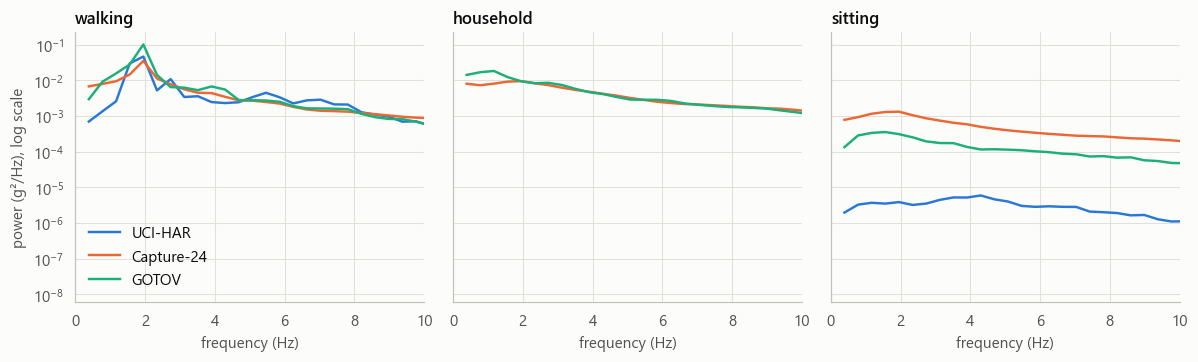

frequency of the highest point of each average spectrum (Hz):


,UCI-HAR,Capture-24,GOTOV
walking,1.950,1.950,1.950
stairs,1.950,NaN,1.560
cycling,NaN,0.390,0.390
household,NaN,1.950,1.170
standing,3.910,1.950,2.340
sitting,4.300,1.950,1.560
lying/sleep,2.730,1.560,1.950
vehicle,NaN,1.560,NaN


median share of the power between 0.5 and 3 Hz:


,UCI-HAR,Capture-24,GOTOV
common,,,
walking,0.690,0.540,0.770
stairs,0.770,NaN,0.580
cycling,NaN,0.090,0.100
household,NaN,0.390,0.480
standing,0.230,0.290,0.260
sitting,0.220,0.140,0.150
lying/sleep,0.230,0.120,0.130
vehicle,NaN,0.290,NaN
other,NaN,0.490,0.790


In [42]:
freq_cols = [f'{f:.3f}' for f in FREQS]


def mean_spectra(psd, mapping):
    psd = psd.assign(common=psd['label'].map(mapping))
    summed = psd.groupby('common')[freq_cols + ['n']].sum()
    return summed[freq_cols].div(summed['n'], axis=0)


c24_psd = pd.concat([pd.read_parquet(E.CACHE / 'capture24' / f'{p}_psd.parquet') for p in c24_pids], ignore_index=True)
spectra = {'UCI-HAR': mean_spectra(pd.read_parquet(E.CACHE / 'uci_psd.parquet'), UCI_TO_COMMON),
           'Capture-24': mean_spectra(c24_psd, C24_TO_COMMON),
           'GOTOV': mean_spectra(pd.read_parquet(E.CACHE / 'gotov_psd.parquet'), GOTOV_TO_COMMON)}

classes = ['walking', 'household', 'sitting']
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharex=True, sharey=True)
for ax, common in zip(axes, classes):
    for name, table in spectra.items():
        if common in table.index:
            ax.plot(FREQS[1:], table.loc[common, freq_cols].to_numpy(float)[1:], color=DATASET_COLOURS[name], label=name)
    ax.set_title(common)
    ax.set_yscale('log')
    ax.set_xlim(0, 10)
    ax.set_xlabel('frequency (Hz)')
axes[0].set_ylabel('power (g²/Hz), log scale')
axes[0].legend()
fig.tight_layout()
plt.show()

peak = pd.DataFrame({name: {c: FREQS[1:][table.loc[c, freq_cols].to_numpy(float)[1:].argmax()] if c in table.index else np.nan for c in COMMON[:-1]} for name, table in spectra.items()})
print('frequency of the highest point of each average spectrum (Hz):')
display(peak.round(2))
share_band = pd.DataFrame({name: d.groupby('common', observed=True)['band_0p5_3hz'].median() for name, d in DATASETS.items()}).reindex(COMMON)
print('median share of the power between 0.5 and 3 Hz:')
display(share_band.round(2))

**How to read this:** walking peaks at about 2 Hz in all three datasets, on both waist and wrist, so a step-frequency feature has a good chance of carrying over between them. The wrist datasets also have more power below 1 Hz. In the sitting panel, UCI sits roughly 100 times or more below the wrist datasets, which fits a waist barely moving when someone sits.

Don't read much into the peak table for the still classes, because there's no repeating movement for it to find. Cycling also needs care: its average spectrum is dominated by a few strong low-frequency windows, while the typical cycling window peaks near 11 Hz (`dom_freq` in 2.6 and 3.6), possibly from road and handlebar vibration.

## 4.8 Which features separate still from moving?

**AUC** is the chance that a randomly chosen moving window has a higher value than a randomly chosen still window. 1.0 is perfect, 0.5 is coin-flipping, and below 0.5 means the feature runs the other way (still windows score higher).

The two Capture-24 columns answer different questions:

- **Physical definition:** still = sitting, standing, lying, and moving = walking, stairs, cycling, household. This one matches UCI.
- **Walmsley definition:** still = sedentary, and moving = light + moderate-vigorous. This is what the current models were scored on, and it counts *standing* as moving.

**The held-out people are left out**, so this table can guide feature choice without using up the test sets. GOTOV is left out too, unless you set `INCLUDE_GOTOV_IN_RANKING` at the top.

The axis-based features (`x_mean`, `y_mean`, `z_mean`, `tilt_z_deg`) depend on how the sensor faces, which differs between devices, so their values only make sense within one dataset.

In [43]:
STILL = ['standing', 'sitting', 'lying/sleep']
MOVING = ['walking', 'stairs', 'cycling', 'household']


def auc_column(df, group_col, still, moving, features, n=300_000):
    chosen = df[df[group_col].astype(str).isin(still + moving)]
    chosen = chosen.sample(min(n, len(chosen)), random_state=SEED)
    y = chosen[group_col].astype(str).isin(moving).to_numpy()
    return pd.Series({f: roc_auc_score(y, chosen[f]) for f in features})


ranking = pd.DataFrame({
    'UCI-HAR': auc_column(uci, 'common', STILL, MOVING, ALL_FEATURES),
    'Capture-24 physical': auc_column(c24_dev, 'common', STILL, MOVING, ALL_FEATURES),
    'Capture-24 physical, no sleep': auc_column(c24_dev, 'common', ['standing', 'sitting'], MOVING, ALL_FEATURES),
    'Capture-24 Walmsley': auc_column(c24_dev, 'label_walmsley', ['sedentary'], ['light', 'moderate-vigorous'], ALL_FEATURES),
})
if INCLUDE_GOTOV_IN_RANKING:
    ranking['GOTOV'] = auc_column(gotov[gotov['common'] != 'other'], 'common', STILL, MOVING, ALL_FEATURES)
strength = (ranking['Capture-24 Walmsley'] - 0.5).abs()     # 0.2 is as strong as 0.8, it just runs the other way
display(ranking.loc[strength.sort_values(ascending=False).index].round(3))

gyro_auc = auc_column(uci, 'common', STILL, MOVING, ['gyro_mag_mean', 'gyro_mag_std'])
print('gyroscope features, UCI only:', gyro_auc.round(3).to_dict())

,UCI-HAR,Capture-24 physical,"Capture-24 physical, no sleep",Capture-24 Walmsley
mag_std,1.000,0.924,0.866,0.831
enmo,1.000,0.907,0.864,0.829
mag_range,1.000,0.914,0.847,0.813
axes_std,0.999,0.914,0.844,0.812
mag_max,1.000,0.906,0.842,0.809
jerk_std,1.000,0.912,0.844,0.800
mag_min,0.001,0.099,0.165,0.203
band_0p5_3hz,0.997,0.812,0.758,0.752
spec_entropy,0.004,0.176,0.247,0.251
mag_mean,0.897,0.780,0.758,0.738


gyroscope features, UCI only: {'gyro_mag_mean': 1.0, 'gyro_mag_std': 0.996}


### The hard pairs

Still vs moving isn't the whole design. SilverGuard also needs to separate the still postures from each other, and this table shows which features can do that within each dataset. High values on the same row across datasets mean a feature is dependable. A value near 0.5 means it's no use for that pair, and a value far below 0.5 is just as useful as one far above it, because only the direction differs.

In [44]:
pairs = {'sitting vs standing': (['sitting'], ['standing']), 'sitting vs lying/sleep': (['lying/sleep'], ['sitting'])}
pair_features = ['mag_mean', 'mag_std', 'axes_std', 'jerk_std', 'band_0p5_3hz', 'spec_entropy', 'x_mean', 'y_mean', 'z_mean', 'tilt_z_deg']
pair_table = {}
for pair, (a, b) in pairs.items():
    pair_table[(pair, 'UCI-HAR')] = auc_column(uci, 'common', a, b, pair_features)
    pair_table[(pair, 'Capture-24')] = auc_column(c24_dev, 'common', a, b, pair_features)
    if INCLUDE_GOTOV_IN_RANKING:
        pair_table[(pair, 'GOTOV')] = auc_column(gotov, 'common', a, b, pair_features)
display(pd.DataFrame(pair_table).round(3))

sitting vs standing            sitting vs lying/sleep           
                         UCI-HAR Capture-24                UCI-HAR Capture-24
mag_mean                   0.918      0.611                  0.870      0.555
mag_std                    0.559      0.675                  0.290      0.857
axes_std                   0.596      0.660                  0.460      0.898
jerk_std                   0.554      0.645                  0.296      0.856
band_0p5_3hz               0.538      0.673                  0.457      0.580
spec_entropy               0.495      0.301                  0.518      0.290
x_mean                     0.626      0.508                  1.000      0.388
y_mean                     0.079      0.455                  0.094      0.505
z_mean                     0.260      0.362                  0.147      0.521
tilt_z_deg                 0.259      0.365                  0.146      0.524

### Does one `mag_std` cut-off carry across datasets?

This finds the best still/moving cut-off in one dataset and applies it to the other. Sleep is left out of the Capture-24 rows. The cut-offs here only show how far the datasets differ, so **don't use these values on the device**. As the plan says, the device threshold should come from your own recordings.

In [45]:
def best_cutoff(df, feature='mag_std'):
    chosen = df[df['common'].isin(STILL + MOVING)]
    y = chosen['common'].isin(MOVING).to_numpy()
    fpr, tpr, cut = roc_curve(y, chosen[feature])
    return cut[(tpr - fpr).argmax()]


def score(df, cutoff, feature='mag_std'):
    chosen = df[df['common'].isin(STILL + MOVING)]
    y = chosen['common'].isin(MOVING).to_numpy()
    moving = chosen[feature].to_numpy() > cutoff
    return {'moving recall': (moving & y).sum() / y.sum(), 'still recall': (~moving & ~y).sum() / (~y).sum()}


c24_dev_awake = c24_dev[c24_dev['common'] != 'lying/sleep']   # sleep is so still that it would flatter any cut-off
rows = []
for source, source_df in {'UCI-HAR': uci, 'Capture-24': c24_dev_awake}.items():
    cutoff = best_cutoff(source_df)
    for target, target_df in {'UCI-HAR': uci, 'Capture-24': c24_dev_awake}.items():
        rows.append({'cut-off chosen on': source, 'mag_std cut-off (g)': cutoff, 'tested on': target, **score(target_df, cutoff)})
transfer = pd.DataFrame(rows).set_index(['cut-off chosen on', 'tested on'])
transfer['balanced'] = (transfer['moving recall'] + transfer['still recall']) / 2
display(transfer.round(3))

mag_std cut-off (g)  moving recall  still recall  balanced
cut-off chosen on tested on                                                             
UCI-HAR           UCI-HAR                   0.090          1.000         0.999     1.000
                  Capture-24                0.090          0.741         0.834     0.788
Capture-24        UCI-HAR                   0.065          1.000         0.999     0.999
                  Capture-24                0.065          0.815         0.774     0.794

**How to read this:** either cut-off is near perfect on UCI, and neither gets above about 0.8 on Capture-24. Moving the cut-off only trades moving recall against still recall, and the balanced score barely changes (0.788 vs 0.794). So the UCI cut-off isn't the main problem. In real life, still and moving windows simply overlap much more, as Section 4.6 shows.

In [46]:
c24_cut = best_cutoff(c24_dev_awake)
for common in ['walking', 'household', 'standing', 'sitting']:
    values = c24_dev_awake.loc[c24_dev_awake['common'] == common, 'mag_std']
    print(f"Capture-24 {common}: {100 * (values > c24_cut).mean():.0f}% of windows are above the {c24_cut:.3f} g cut-off")

Capture-24 walking: 81% of windows are above the 0.065 g cut-off
Capture-24 household: 80% of windows are above the 0.065 g cut-off
Capture-24 standing: 41% of windows are above the 0.065 g cut-off
Capture-24 sitting: 21% of windows are above the 0.065 g cut-off


## 4.9 Why the current model misses "moving" windows

The earlier result was that all three methods catch only about 60% of moving windows on Capture-24. This looks at what's inside the Walmsley `light` class, which got the lowest score.

In [47]:
inside = pd.crosstab(c24_dev['label_specific'].astype(str), c24_dev['label_walmsley'].astype(str), normalize='columns') * 100
inside = inside.reindex(columns=['sedentary', 'light', 'moderate-vigorous'])
inside = inside[inside.sum(axis=1) > 0]
print('what each Walmsley class is made of (% of its windows, development people only):')
display(inside.sort_values('light', ascending=False).round(1))

low_motion = c24_dev[c24_dev['label_walmsley'].astype(str).isin(['sedentary', 'light'])]
compare = low_motion.groupby([low_motion['label_walmsley'].astype(str), low_motion['label_specific'].astype(str)])[['mag_std', 'axes_std']].median()
print('median movement within sedentary and light:')
display(compare[compare.index.get_level_values(1).isin(['sitting', 'vehicle', 'standing', 'household-chores', 'walking', 'mixed-activity'])].round(3))
light_windows = c24_dev[c24_dev['label_walmsley'].astype(str) == 'light']
missed = light_windows[light_windows['mag_std'] <= c24_cut]
print(f"{100 * len(missed) / len(light_windows):.0f}% of light windows are at or below the {c24_cut:.3f} g cut-off. What those missed windows are (%):")
print((100 * missed['label_specific'].astype(str).value_counts(normalize=True)).round(1).to_string())
print('share of Capture-24 "standing" windows below the median mag_std of "sitting":',
      f"{100 * (c24_dev.loc[c24_dev['common'] == 'standing', 'mag_std'] < c24_dev.loc[c24_dev['common'] == 'sitting', 'mag_std'].median()).mean():.0f}%")

what each Walmsley class is made of (% of its windows, development people only):


label_walmsley,sedentary,light,moderate-vigorous
label_specific,,,
household-chores,0.100,37.000,0.500
walking,0.000,30.600,14.600
standing,0.000,17.200,0.000
mixed-activity,0.000,12.400,41.500
manual-work,0.000,2.600,11.900
sports,0.000,0.200,11.400
bicycling,0.000,0.000,20.100
sitting,90.300,0.000,0.000
vehicle,9.600,0.000,0.000


median movement within sedentary and light:


mag_std  axes_std
label_walmsley label_specific                     
light          household-chores    0.146     0.404
               mixed-activity      0.096     0.239
               standing            0.043     0.117
               walking             0.164     0.358
sedentary      household-chores    0.069     0.239
               sitting             0.011     0.035
               vehicle             0.066     0.111

29% of light windows are at or below the 0.065 g cut-off. What those missed windows are (%):
label_specific
standing           34.700
household-chores   24.800
walking            21.700
mixed-activity     16.500
manual-work         1.700
sports              0.500
share of Capture-24 "standing" windows below the median mag_std of "sitting": 25%


---
# Part 5: Findings and next steps

## What the datasets offer

| | UCI-HAR | Capture-24 | GOTOV |
|---|---|---|---|
| **Best used for** | Comparison only | Training and development | Independent check on older adults |
| **Main strength** | Has a gyroscope, clean labels | Real life, whole days, many people | Older adults, wrist, specific activities |
| **Main weakness** | Waist, young, scripted, 3.7 h | No gyroscope, age only in bins, camera-based labels | No gyroscope, scripted, small, mostly in their 60s |

## Findings

**1. Neither new dataset can test the gyroscope (4.2).** 213 of UCI's 561 features need it. On UCI, gyro features didn't beat the accelerometer for still vs moving, since both already reach about 1.0 (4.8). That says nothing about the wrist. So the activity work can stay accelerometer-only, but the gyro side of the fall rule needs the fall datasets.

**2. Still windows are what changes between lab and real life (4.6).** Median `mag_std` for standing rises from 0.003 g on UCI to 0.041 g on Capture-24. At a 0.065 g cut-off, 41% of Capture-24 standing and 21% of sitting look like movement, and 19% of walking looks still. This is likely why training on Capture-24 gave no gain over the UCI model in your earlier run: the overlap is in the data itself.

**3. No single new feature beats `mag_std` for still vs moving (4.8).** It's first on all three Capture-24 scoring definitions (0.87 without sleep, 0.83 on Walmsley), with `enmo` right behind it. **This only tests one feature at a time**, so a combination could still do better. That experiment is still open, and it's already in your plan.

**4. The label definition costs some of the score (4.8, 4.9).** Walmsley counts standing as moving. Under a physical definition, the `mag_std` AUC rises from 0.83 to 0.87, though that definition also drops mixed classes such as `mixed-activity` and `vehicle`. Standing is the largest single group in the missed `light` windows at 35%, but that leaves 65% as chores, walking and mixed activity, so standing doesn't explain everything.

**5. Wrist orientation didn't separate sitting from sleep, but time of day does (2.5, 4.8).** The best single axis reached only about 0.61 on the wrist, compared with 1.00 for UCI's waist, where lying down turns the whole sensor. Meanwhile, sleep makes up 99 to 100% of labelled windows from midnight to 3 am and under 1% at 9 am. This supports what `context.md` predicted, and the uncertain hours are around 6 am and 10 to 11 pm. Sleep labels come partly from diaries, and I only tested raw tilt per 2.56 s window, not longer windows or a tilt-change feature.

**6. Each dataset has its own calibration error (4.4).** About +24 mg on UCI, +14 mg on GOTOV and about 0 on Capture-24. A threshold on the raw magnitude or ENMO won't transfer cleanly. `mag_std` is largely unaffected, because a constant offset doesn't change the spread much.

**7. Walking looks similar everywhere in frequency (4.7).** All three peak at about 2 Hz, and the typical cycling window peaks near 11 Hz in both wrist datasets. Frequency features look worth including in the combination test.

## Data problems to handle

| Dataset | Problem | What to do |
|---|---|---|
| GOTOV | The documents say 83 Hz and 88 Hz, but the timestamps give **85.7 Hz** | Resample from timestamps, as `eda_features.py` does |
| GOTOV | The wrist files hold 1,451 of the 1,579 minutes claimed. Five people are missing over 5 minutes, and only 21 have walking and 18 have cycling | Check per-activity counts before splitting people, and don't rely on the summary file |
| GOTOV | Two people are just under the stated minimum age of 60, and the recording dates don't match the PDF | Say "about 60 and over" in the report |
| GOTOV | Same row counts in two pairs of files | Checked: the data differs, so these aren't duplicates |
| GOTOV | Labels are the protocol's start and end times, so bout edges may include transitions. I kept those windows | Consider trimming bout edges in a later test |
| Capture-24 | Only about 68% of a typical recording is labelled | Never treat unlabelled time as "nothing happened" |
| Capture-24 | Worn on the dominant wrist ([paper](https://arxiv.org/abs/2402.19229)), which may show more hand movement than the other wrist | Agree which wrist the watch goes on, and note it in the report if it differs |
| UCI | The highest reading is 2.2 g | It can't be used to test the 2.5 to 3 g fall spike |

## Things in the current plan worth changing

1. **Don't expect GOTOV to show a "drop" (`next_steps.ipynb`, Section 1).** The plan says to report the drop against Capture-24. Its still classes look cleaner, so the score may well go **up**. That wouldn't mean the model suits older adults better, only that scripted data is easier. Report it that way. I haven't scored any model on GOTOV, and I kept it out of the feature ranking so it can still serve as a fair test.
2. **You have 109 more Capture-24 people available.** Your models trained on 31 of the 140 non-test people. The extra 109 are **all under 53**, because all 34 people aged 53+ were already in your 42. More people should help, but the age mix moves from mostly 53+ to mostly younger, so train it both ways and compare on the existing 11 test people only once.
3. **Keep the 11 test people out.** They appear in the descriptive tables, but not in the AUC ranking, the cut-offs or Section 4.9, so they're still usable as a test set.

## What none of these datasets can tell you

- **Frail or very old adults.** Only 5 GOTOV participants are 70 or over and 1 is 75 or over, and they were selected to be free of movement restrictions and able to bring a bike. Capture-24 can't be split above 53. The report should state this limit.
- **Falls.** None of the three contains falls, so that work still needs WEDA-FALL and the other fall datasets.
- **The MPU-6050.** These are different sensors, which is why the final threshold should still come from your own recordings.

## Suggested next steps

1. Run the feature-combination experiment on Capture-24's non-test people: `mag_std`, `axes_std`, frequency features and longer windows, compared with the `mag_std` threshold.
2. Add time of day to the sleep logic, using the uncertain hours in 2.5 to decide how it should behave.
3. Score the final choice once on the 11 test people and on GOTOV, and report the two separately.

## In plain language

This notebook checks what's inside each dataset before any more modelling depends on it. UCI records a phone on the waist of young adults following instructions. Capture-24 records a wrist device on 151 people going about a normal day, and GOTOV records a wrist device on 35 people aged around 60 and up following instructions. Neither new dataset has a gyroscope, so they only help with the accelerometer side of the project.

The main difference is how "still" looks. On UCI, someone standing barely registers any movement. In daily life, people standing are often using their hands, so the signal overlaps with real movement, and that makes real-life data much harder than UCI. GOTOV sits closer to UCI because it's scripted, so a high score there wouldn't be proof of working in everyday life. The best single measure is still `mag_std`, the feature you already use, although combinations haven't been tested yet. To tell sleep from sitting, the wrist's angle barely helped in this test, while the time of day helped a lot.